## 1. Importation des bibliothèques fondamentales

- **Objectif** : Charger les librairies de base indispensables pour la manipulation des données (Pandas, NumPy) et la création de visualisations (Matplotlib, Seaborn).

In [16]:
# Importation des bibliothèques fondamentales
import matplotlib.pyplot as np
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import squarify

print("✅ Bibliothèques importées avec succès !")

✅ Bibliothèques importées avec succès !


## 1.1 Ingestion des données brutes
Nous chargeons ici nos fichiers sources. 

In [17]:
Sales = pd.read_csv("Sales_cleaned_silver.csv")
print("Importation du fichier avec succès")

Importation du fichier avec succès


## 2. Configuration du Design System (Charte Graphique B2B)

- **Objectif** : Définir les variables globales de couleurs, les styles d'axes et la typographie pour garantir une identité visuelle professionnelle et cohérente sur tous les graphiques.

In [18]:
# ==========================================
# DESIGN SYSTEM / CHARTE GRAPHIQUE B2B
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Palette de couleurs sémantiques
PRIMARY_COLOR = "#1F4E79"    # Bleu marine corporate (barres principales, tendances)
ACCENT_COLOR = "#D35400"     # Orange corail / Ambre (mise en avant, alertes, records)
SECONDARY_COLOR = "#3498DB"  # Bleu clair / Turquoise (comparaisons, catégories)
GRAY_SLATE = "#7F8C8D"       # Gris ardoise (éléments secondaires)
TEXT_COLOR = "#2C3E50"       # Gris foncé / Noir doux pour les textes et titres
GRID_COLOR = "#E2E8F0"       # Gris très clair pour les grilles épurées

# Palette globale pour les graphiques multi-catégories (camemberts, barplots...)
COLOR_PALETTE = [PRIMARY_COLOR, ACCENT_COLOR, SECONDARY_COLOR, GRAY_SLATE]

# 2. Configuration globale de Matplotlib & Seaborn
sns.set_theme(style="whitegrid")  # Fond blanc avec grilles horizontales légères

# 3. Paramètres globaux (rcParams) - Tout s'applique automatiquement !
plt.rcParams.update({
    # Dimensions et résolution par défaut
    "figure.figsize": (12, 6),
    "figure.dpi": 300,
    
    # Polices et couleurs globales
    "font.family": "sans-serif",
    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    
    # Tailles et graisses automatiques (Finit les .fontsize à répéter !)
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    
    # Style de la grille et des axes
    "axes.edgecolor": GRID_COLOR,
    "axes.linewidth": 1.0,
    "grid.color": GRID_COLOR,
    "grid.linestyle": "--",
    "grid.alpha": 0.6,
    
    # Style des lignes par défaut (pour les lineplots)
    "lines.linewidth": 2.5,
    "lines.markersize": 7,
})

print("🎨 Design System complet appliqué avec succès !")

🎨 Design System complet appliqué avec succès !


## 📊 Tableau de Bord : KPIs et Objectifs Stratégiques

Cette section regroupe les indicateurs clés de performance (KPIs) essentiels pour le pilotage commercial et l'analyse de la valeur des Régions.

### 1. Indicateurs Clés de Performance (KPIs) Globaux

- **Chiffre d'Affaires Total (CA) :** Somme globale des revenus générés sur la période.
- **Nombre de Clients Actifs :** Volume total de clients uniques ayant passé au moins une commande.
- **Panier Moyen (Average Order Value - AOV) :** Montant moyen dépensé par commande ($CA / Nombre de commandes$).
- **Quantité Totale Vendue :** Volume total d'articles écoulés.

In [19]:
print("--- Analyse du Chiffre d'Affaires par Région ---")

# 1. Calculer le CA total par région en groupant les données
# On regroupe par la colonne RegionName et on somme les prix totaux
ca_total_regions = Sales.groupby("RegionName")["TotalPrice"].sum().reset_index()

# 2. Calculer le pourcentage de chaque région par rapport au CA global
# On divise le CA de la région par la somme totale de tous les CA, puis on multiplie par 100
ca_total_regions["pourcentage %"] = (ca_total_regions['TotalPrice'] / ca_total_regions['TotalPrice'].sum()) * 100

# 3. Trier du plus grand au plus petit pour voir les régions les plus performantes en premier
# ascending=False permet d'avoir l'ordre décroissant (du Top 1 au dernier)
ca_total_regions = ca_total_regions.sort_values(by='TotalPrice', ascending=False).reset_index(drop=True)

# ==========================================
# 4. PARTIE MAPPAGE ET FORMATAGE DES DONNÉES
# ==========================================
# Le "mapping" (.map()) sert ici à transformer des valeurs brutes (nombres décimaux) 
# en chaînes de caractères (strings) propres, lisibles pour un être humain et prêtes pour un rapport.

# A. Formatage du chiffre d'affaires en euros avec séparateur de milliers et 2 décimales (ex: 12,345.67 €)
ca_total_regions['TotalPrice_formatted'] = ca_total_regions['TotalPrice'].map('{:,.2f} €'.format)

# B. Formatage du pourcentage avec l'ajout du symbole '%' et 2 chiffres après la virgule (ex: 15.50 %)
ca_total_regions['pourcentage_formatted'] = ca_total_regions['pourcentage %'].map('{:.2f} %'.format)

# ==========================================
# 5. PARTIE STRUCTURATION DU TABLEAU FINAL
# ==========================================
# A. Sélection des colonnes formatées et "propres" que l'on souhaite conserver pour la présentation
tableau_final = ca_total_regions[['RegionName', 'TotalPrice_formatted', 'pourcentage_formatted']]

# B. Renommage des colonnes techniques en libellés explicites et professionnels pour le dashboard/rapport
tableau_final.columns = ['Région', 'Chiffre d\'Affaires', 'Part du CA (%)']

print("Tableau de la répartition du Chiffre d'Affaires par région :")
# Affichage interactif du tableau final propre dans le notebook
display(tableau_final)

--- Analyse du Chiffre d'Affaires par Région ---
Tableau de la répartition du Chiffre d'Affaires par région :


,Région,Chiffre d'Affaires,Part du CA (%)
0,South,"664,214.00 €",27.70 %
1,West,"638,180.00 €",26.61 %
2,North,"562,255.00 €",23.45 %
3,East,"533,321.00 €",22.24 %


### 💡 Analyse et Interprétation des Résultats Géographiques

* **Le duo de tête (plus de 600 k€) :** Le **Sud (South)** et l'**Ouest (West)** s'imposent comme les deux principales locomotives commerciales de l'entreprise. Chacune de ces deux régions dépasse la barre symbolique des 600 000 € de chiffre d'affaires, captant à elles seules plus de la moitié de la valeur globale.
* **La contribution des autres régions :** Le **Nord (North)** et l'**Est (East)** affichent également des performances solides et soutiennent activement l'activité, s'inscrivant dans la continuité directe du peloton de tête.
* **Une répartition globalement homogène :** Malgré un léger ascendant des régions Sud et Ouest, la répartition du chiffre d'affaires est remarquablement équilibrée sur l'ensemble du territoire. On observe en effet un écart de **seulement environ 5 points de pourcentage** entre la première région (**South** à 27,70 %) et la dernière (**East** à 22,24 %). 
* **Conclusion stratégique :** Cet équilibre démontre une excellente pénétration du marché et une diversification saine des risques géographiques, l'entreprise ne dépendant pas d'une seule zone ultra-dominante.

### 2.1 Visualisation graphique de la répartition géographique

Pour compléter l'analyse tabulaire, le diagramme circulaire ci-dessous permet d'apprécier visuellement l'équilibre des parts de marché entre les quatre régions. La région **East** est légèrement détachée pour mettre en valeur la structure globale[cite: 1].

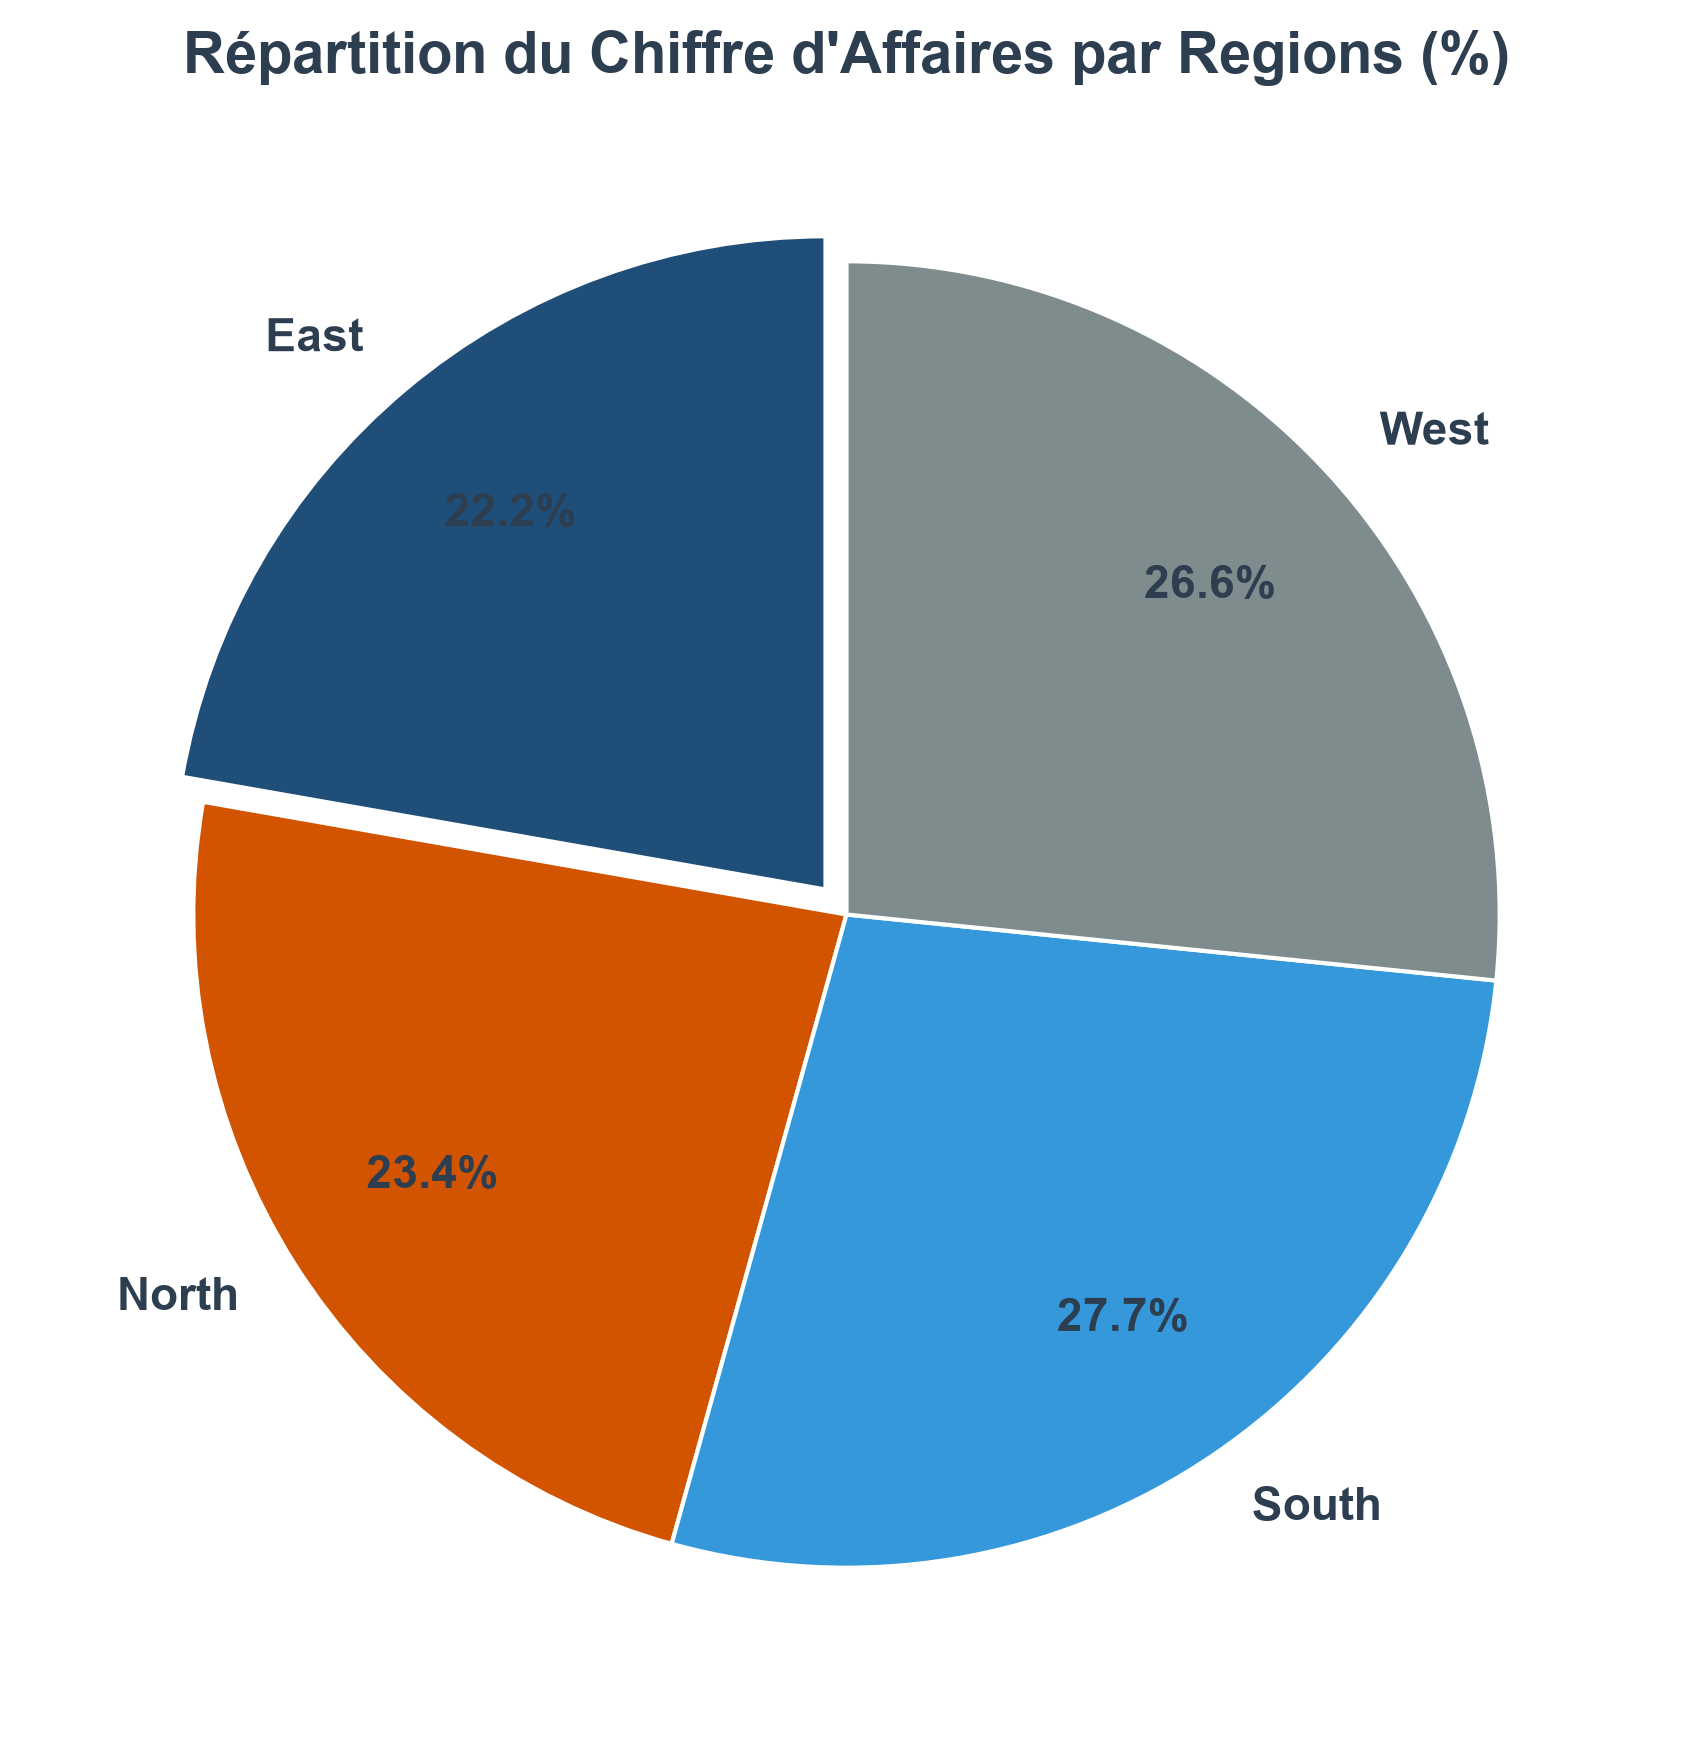

In [20]:
# Préparation des données (spécifique à l'analyse)
ca_total_regions = Sales.groupby("RegionName")["TotalPrice"].sum().reset_index()

# Choix ponctuel : décaler légèrement la première tranche pour l'isoler visuellement
mon_decalage = [0.05, 0, 0, 0] 

# Création de la figure (prend automatiquement la taille (12, 6) du rcParams)
plt.figure()

plt.pie(
    ca_total_regions["TotalPrice"],
    labels=ca_total_regions["RegionName"],
    autopct='%1.1f%%',
    startangle=90,
    colors=COLOR_PALETTE[:4],    # On pioche automatiquement les 2 premières couleurs de notre charte !
    explode=mon_decalage,        # Logique locale (propre à ce graphique)
    pctdistance=0.75,
    textprops={'weight': 'bold'} # La taille s'adapte, on garde juste le 'bold' si besoin
)

# Le titre récupère sa taille (14) et son gras (bold) directement du rcParams
plt.title("Répartition du Chiffre d'Affaires par Regions (%)")

plt.tight_layout()
plt.show()

### 💡 Interprétation de la visualisation

* **Équilibre visuel :** Le graphique en camembert confirme la répartition très homogène du chiffre d'affaires sur le territoire. Aucune région ne monopolise à elle seule le marché[cite: 1].
* **Complémentarité des zones :** Le cumul des deux régions de tête (**South** à 27,7 % et **West** à 26,6 %) représente un peu plus de 54 % de l'activité totale, tandis que les régions **North** (23,4 %) et **East** (22,2 %) soutiennent solidement le reste des ventes[cite: 1].

### 2.2 Analyse multicritères des profils régionaux (Radar Chart)

Pour aller au-delà du simple chiffre d'affaires et croiser plusieurs dimensions clés de la performance, nous construisons ci-dessous un graphique en étoile (*radar chart*). Ce dernier évalue simultanément quatre indicateurs normalisés (de 0 % à 100 %) pour chaque région :
* Le **Chiffre d'Affaires total** (valeur brute)
* Le **Panier moyen** (valeur par commande)
* Le **Volume de commandes** (fréquence d'achat)
* Les **Clients uniques** (taille de la base client active)

  RegionName  CA_Total  Panier_Moyen  Nb_Commandes  Clients_Uniques
0       East    533321   2259.834746           236                8
1      North    562255   2323.367769           242                8
2      South    664214   2236.410774           297                8
3       West    638180   2381.268657           268                8


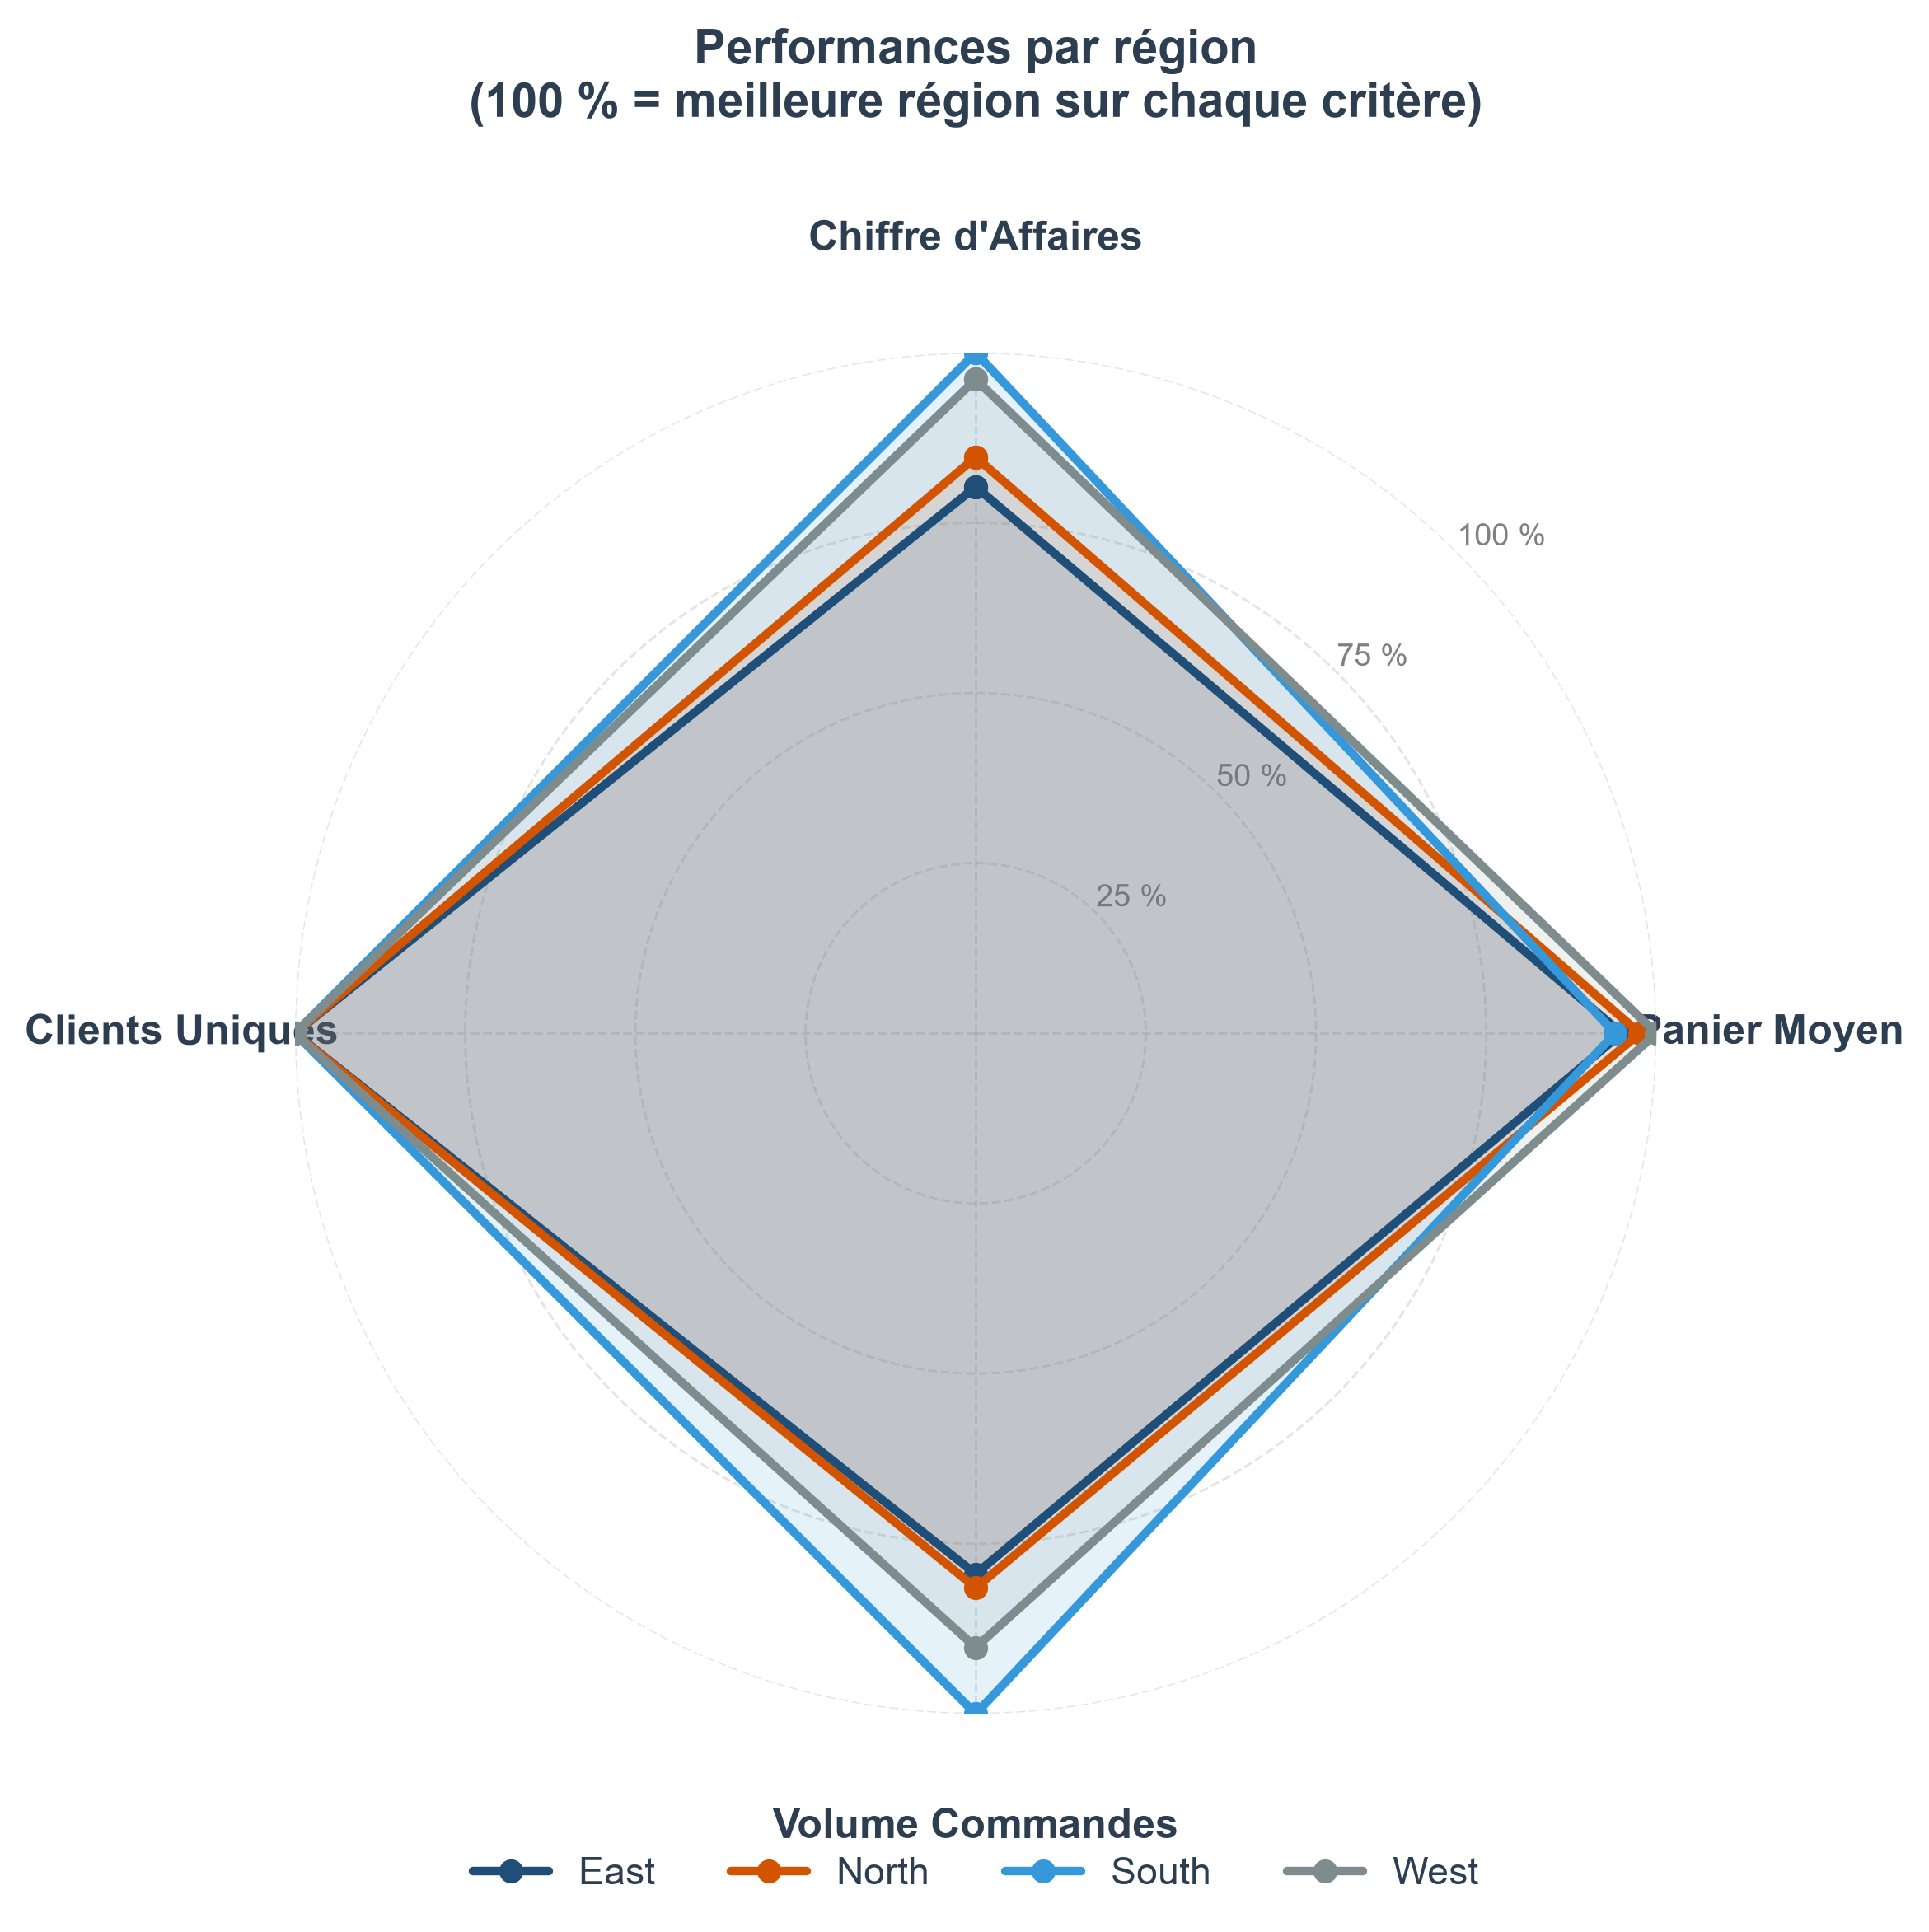

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# ÉTAPE 1 : agrégation (inchangée)
radar_df = Sales.groupby("RegionName").agg(
    CA_Total=('TotalPrice', 'sum'),
    Panier_Moyen=('TotalPrice', 'mean'),
    Nb_Commandes=('TotalPrice', 'count'),
    Clients_Uniques=('CustomerID', 'nunique')
).reset_index()

print(radar_df)  # à vérifier : Clients_Uniques est-il identique partout ?

metrics = ['CA_Total', 'Panier_Moyen', 'Nb_Commandes', 'Clients_Uniques']
categories = ["Chiffre d'Affaires", "Panier Moyen", "Volume Commandes", "Clients Uniques"]

# ÉTAPE 2 : normalisation par le maximum (100 % = meilleure région)
radar_norm = radar_df.copy()
radar_norm[metrics] = radar_df[metrics] / radar_df[metrics].max()

# ÉTAPE 3 : radar
N = len(metrics)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles_loop = angles + angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)   # 1er axe en haut
ax.set_theta_direction(-1)       # sens horaire

for i, row in radar_norm.iterrows():
    vals = row[metrics].astype(float).tolist()
    vals += vals[:1]
    color = COLOR_PALETTE[i]
    ax.plot(angles_loop, vals, linewidth=2.5, marker='o', markersize=6,
            label=row['RegionName'], color=color)
    ax.fill(angles_loop, vals, color=color, alpha=0.12)

# Axes et graduations
ax.set_xticks(angles)
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
ax.tick_params(axis='x', pad=20)             # écarte les labels du cercle
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["25 %", "50 %", "75 %", "100 %"], color="grey", size=9)
ax.set_rlabel_position(45)                   # graduations entre deux axes
ax.grid(color="lightgrey", linestyle="--", linewidth=0.7)
ax.spines['polar'].set_visible(False)

# Titre et légende
ax.set_title("Performances par région\n(100 % = meilleure région sur chaque critère)",
             size=14, fontweight='bold', pad=30)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4, frameon=False)

plt.tight_layout()
plt.show()

### 💡 Interprétation et Bilan du Profil Multicritères

* **Une homogénéité structurelle remarquable :** Les polygones des quatre régions se superposent presque parfaitement, formant un profil très proche. Cela démontre que les dynamiques commerciales sont extrêmement régulières d'une zone à l'autre.
* **Absence de distorsion majeure :** Aucune région ne présente de profil atypique (comme un panier moyen très élevé couplé à un volume d'achat minime). Les performances s'équilibrent de manière cohérente sur l'ensemble des dimensions analysées.
* **Validation stratégique :** L'aspect resserré et symétrique de ce graphique confirme la bonne répartition des risques et la solidité du modèle commercial B2B de l'entreprise sur l'ensemble du territoire.

### 2.3 Répartition du mix produits par région (Barres empilées 100 %)

Afin de vérifier si les habitudes de consommation varient d'une zone géographique à une autre, nous analysons ici le poids relatif des différentes catégories de produits dans le chiffre d'affaires de chaque région. Ce graphique en barres empilées normalisées à 100 % permet d'isoler la structure du mix-produits indépendamment du volume global des ventes.

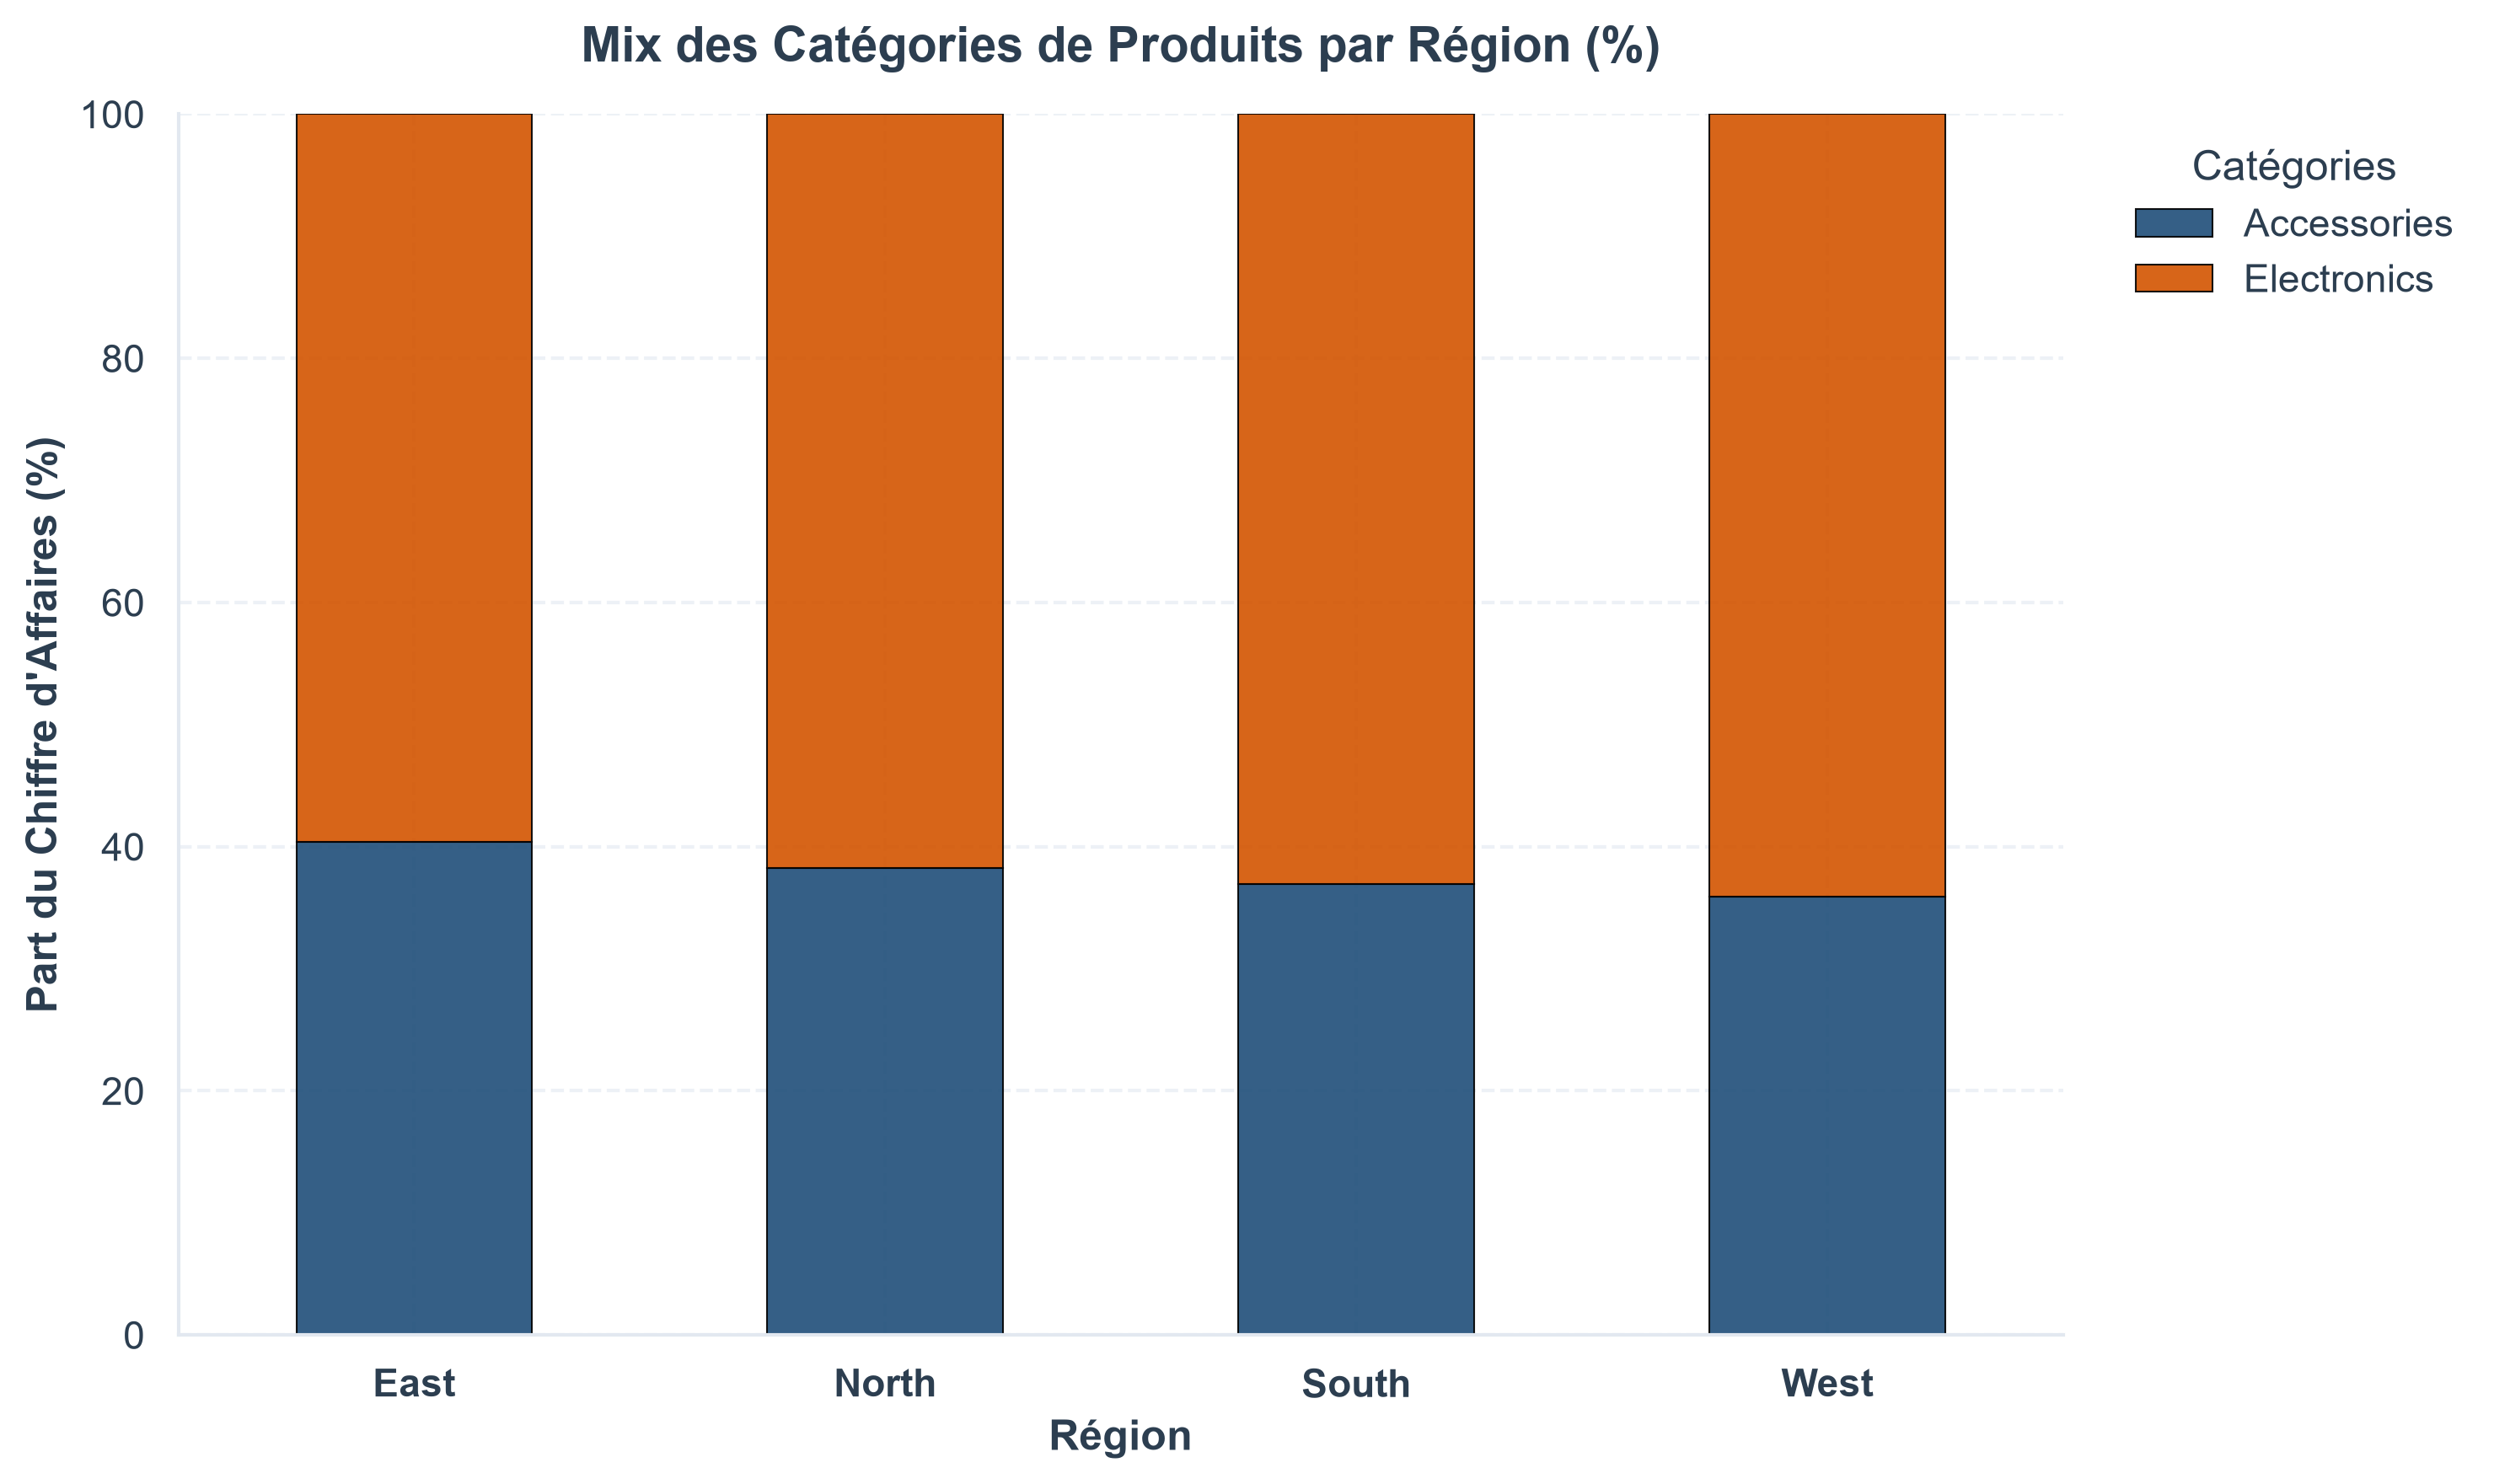

In [22]:
# ==========================================
# ÉTAPE 2.3 : Mix des Catégories par Région (Barres empilées 100%)
# ==========================================

# 1. Création d'un tableau croisé normalisé en pourcentage par ligne (région)
region_cat = pd.crosstab(
    Sales['RegionName'], 
    Sales['Category'], 
    values=Sales['TotalPrice'], 
    aggfunc='sum', 
    normalize='index'
) * 100

# 2. Création de la figure
fig, ax = plt.subplots(figsize=(10, 6))

region_cat.plot(
    kind='bar', 
    stacked=True, 
    ax=ax, 
    color=COLOR_PALETTE[:len(region_cat.columns)],
    edgecolor='black',
    linewidth=0.5,
    alpha=0.9
)

# 3. Mise en forme
plt.title("Mix des Catégories de Produits par Région (%)", size=14, fontweight='bold', pad=15)
plt.xlabel("Région", fontweight='bold')
plt.ylabel("Part du Chiffre d'Affaires (%)", fontweight='bold')
plt.xticks(rotation=0, fontweight='bold')

# Légende propre à l'extérieur
plt.legend(title="Catégories", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)

ax.set_ylim(0, 100)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### 💡 Interprétation du mix-produits par région

* **Stabilité remarquable du mix-produits :** Le graphique met en evidence une constance presque parfaite d'une région à l'autre. La catégorie **Electronics** représente systématiquement la majeure partie du chiffre d'affaires (oscillant autour de 60 %), tandis que les **Accessories** complètent le solde à hauteur d'environ 40 %.
* **Absence de spécificité culturelle ou régionale :** Contrairement à ce que l'on pourrait observer dans d'autres secteurs, il n'existe pas de surconsommation ou de désaffection locale pour l'une ou l'autre des catégories. Le profil d'achat des clients B2B est homogène sur tout le territoire.
* **Confirmation de la maturité du portefeuille :** Cette régularité conforte l'idée d'un jeu de données et d'un modèle commercial extrêmement stables, où la répartition des ventes ne dépend pas de particularismes régionaux.

### 2.4 Analyse de la saisonnalité et des dynamiques temporelles (Heatmap)

Pour compléter notre étude géographique et s'assurer qu'aucun phénomène saisonnier n'est masqué par les visions annuelles globales, nous croisons ici les **régions** et les **mois de l'année** sous forme d'une carte de chaleur (*heatmap*). L'intensité de la couleur traduit le volume de chiffre d'affaires généré, permettant d'identifier d'éventuels pics ou creux d'activité localisés.

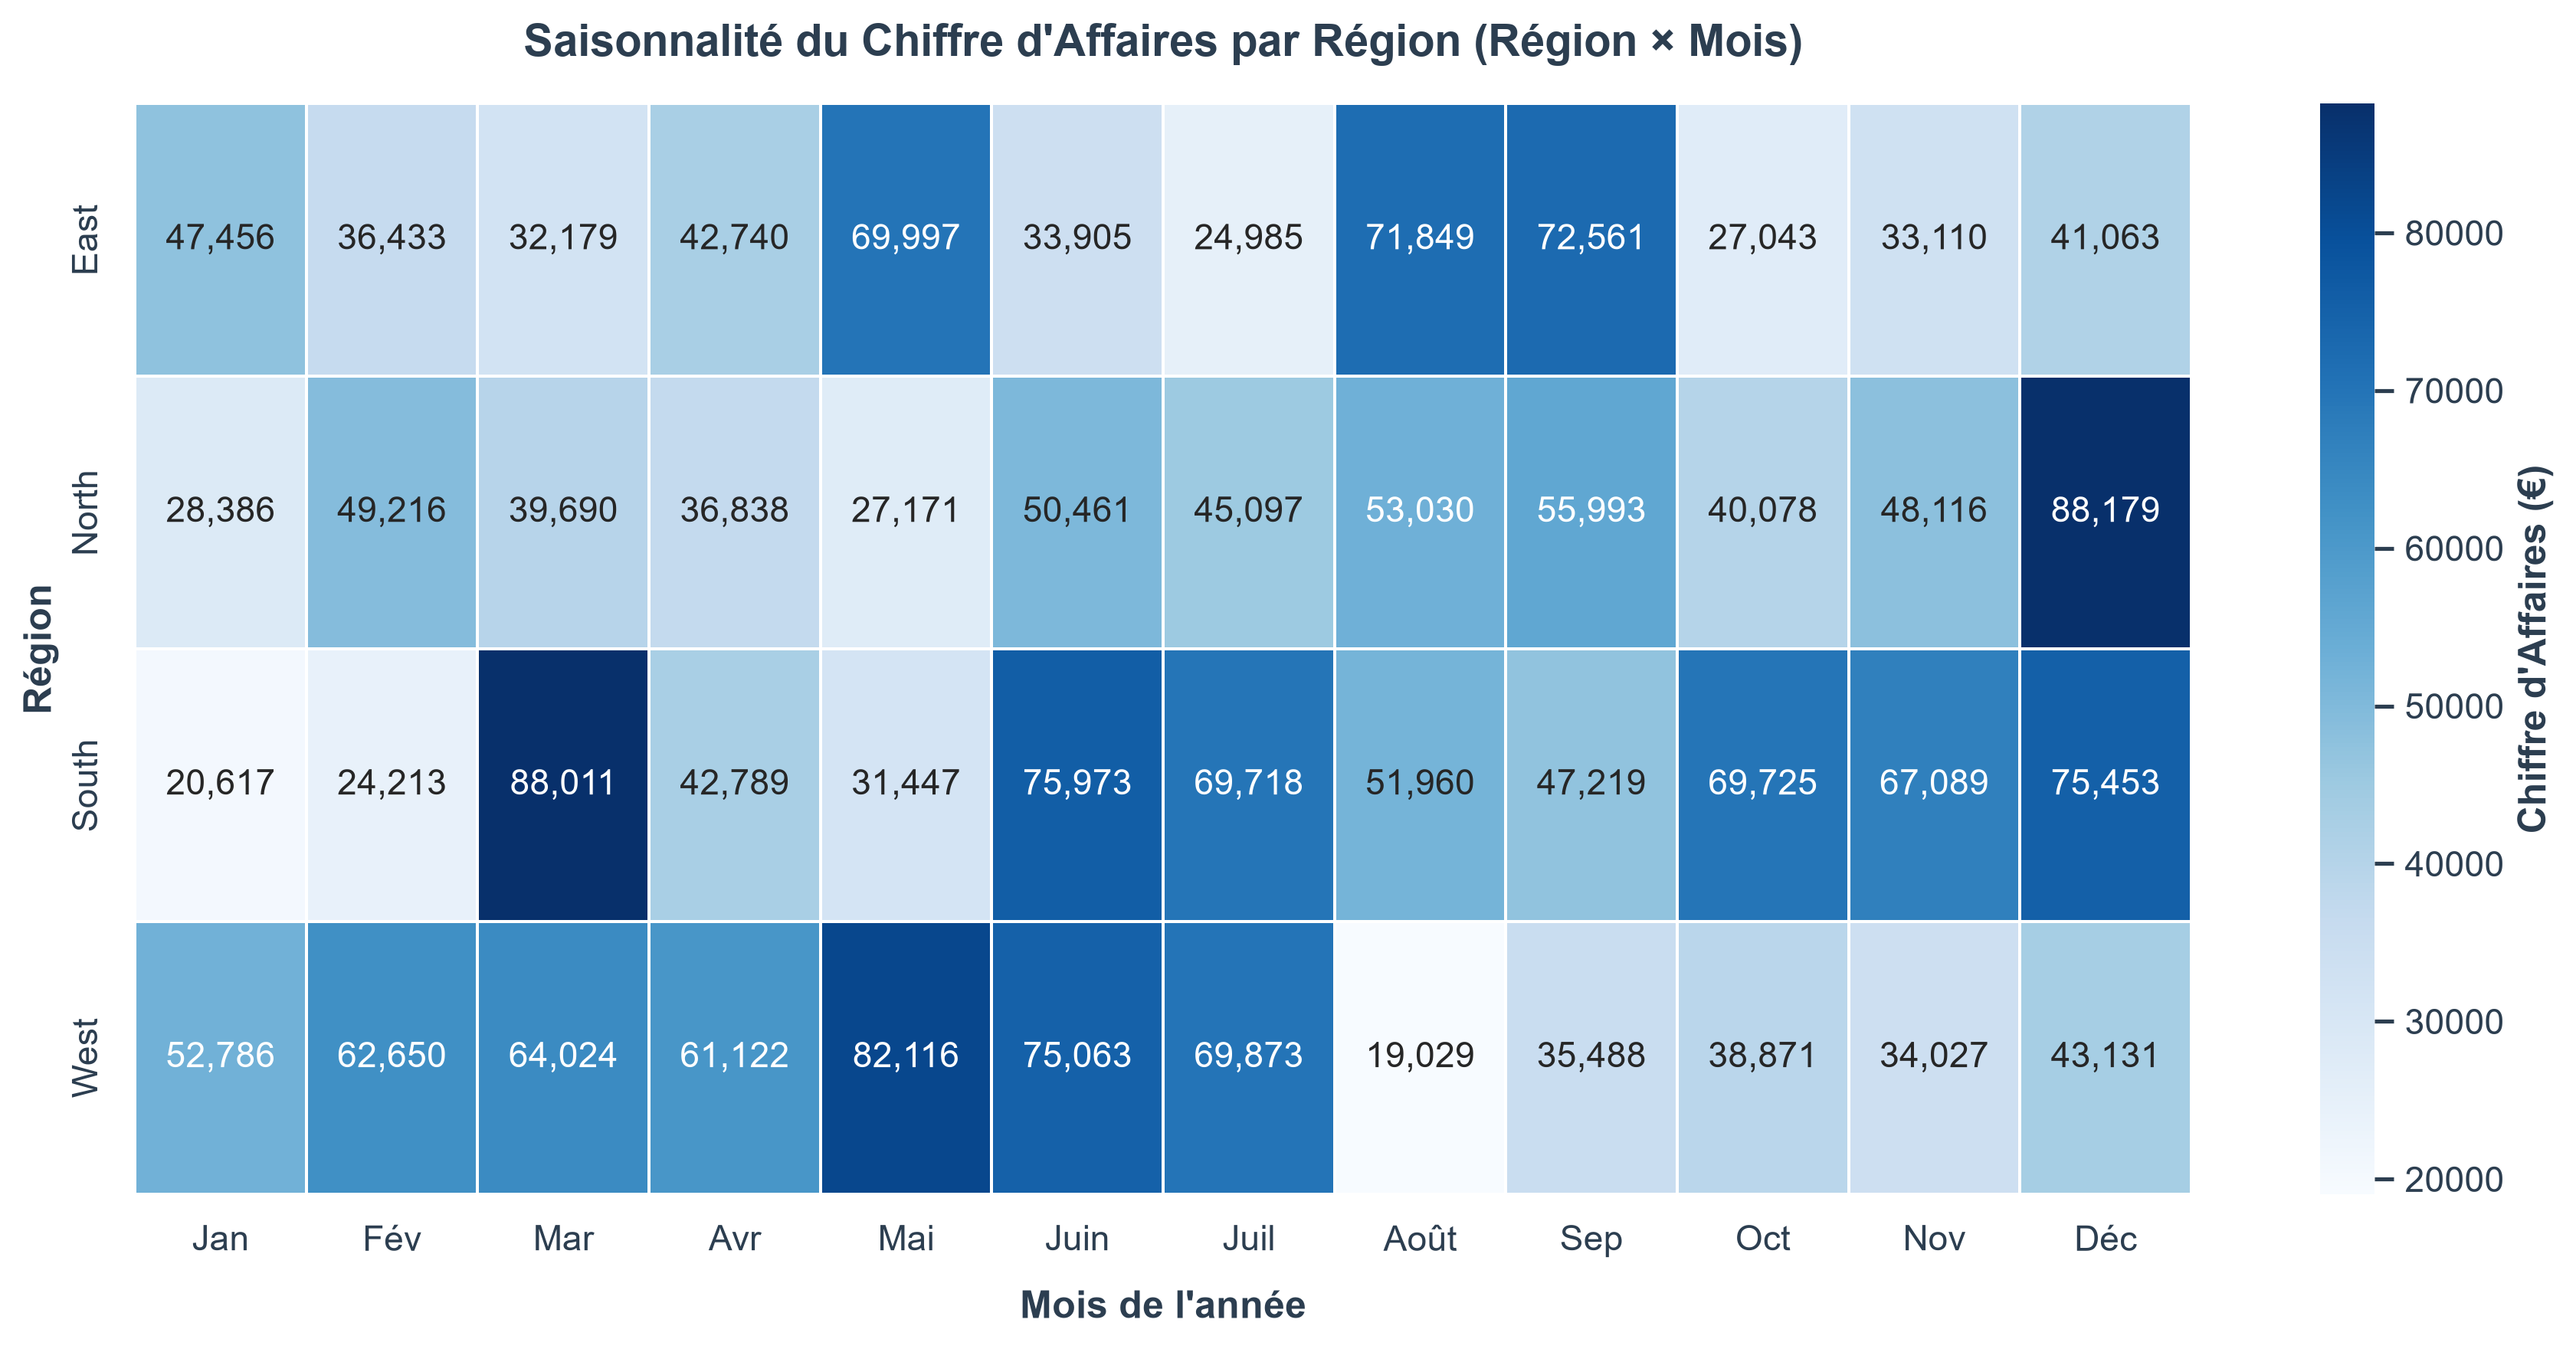

In [23]:
# ==========================================
# ÉTAPE 2.4 : Heatmap de Saisonnalité (Région × Mois)
# ==========================================

# Utilisation directe de la colonne 'OrderMonth' que tu viens de créer
heatmap_df = Sales.pivot_table(
    index='RegionName', 
    columns='OrderMonth', 
    values='TotalPrice', 
    aggfunc='sum'
)

# Création de la figure
fig, ax = plt.subplots(figsize=(12, 6))

# Tracé de la heatmap
sns.heatmap(
    heatmap_df, 
    cmap='Blues', 
    annot=True, 
    fmt=',.0f', 
    linewidths=0.5, 
    cbar_kws={'label': 'Chiffre d\'Affaires (€)'},
    ax=ax
)

# Mise en forme
plt.title("Saisonnalité du Chiffre d'Affaires par Région (Région × Mois)", size=14, fontweight='bold', pad=15)
plt.xlabel("Mois de l'année", fontweight='bold', labelpad=10)
plt.ylabel("Région", fontweight='bold')

month_names = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']
ax.set_xticklabels(month_names[:heatmap_df.shape[1]], rotation=0)

plt.tight_layout()
plt.show()

### 💡 Analyse approfondie de la saisonnalité par région

* **Des profils saisonniers marqués et hétérogènes :** Contrairement à l'homogénéité observée sur les volumes annuels globaux, la carte de chaleur met en évidence des dynamiques temporelles très contrastées d'une région à l'autre.
* **Le secret de la performance du Sud :** La suprématie de la région *South* s'explique par sa capacité à enchaîner de nombreux mois à forte valeur (plusieurs mois au-delà de 69 000 €), lui assurant une assise financière stable toute l'année.
* **Des temporalités de pics spécifiques :** 
  * Le *Nord* se distingue par un effet de fin d'année ultra-dominant en décembre (88 179 €).
  * L'*Ouest* réalise l'essentiel de sa performance forte entre le printemps et le début de l'été (mars à juillet).
  * L'*Est* concentre ses sursauts sur des mois ciblés comme mai, août et septembre.
* **Conclusion opérationnelle :** Cette segmentation temporelle valide l'intérêt d'une stratégie commerciale adaptée aux calendriers locaux plutôt qu'un lissage uniforme.

### 2.5 Distribution et dispersion des montants de commandes (Boxplot)

Afin de vérifier si les volumes de vente globaux cachent des disparités dans la taille des transactions unitaires, nous analysons ici la distribution statistique des montants de commandes par région. Ce boxplot met en évidence la médiane, les quartiles et l'impact des commandes exceptionnelles (*outliers*).

C:\Users\mboum\AppData\Local\Temp\ipykernel_36656\496041065.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


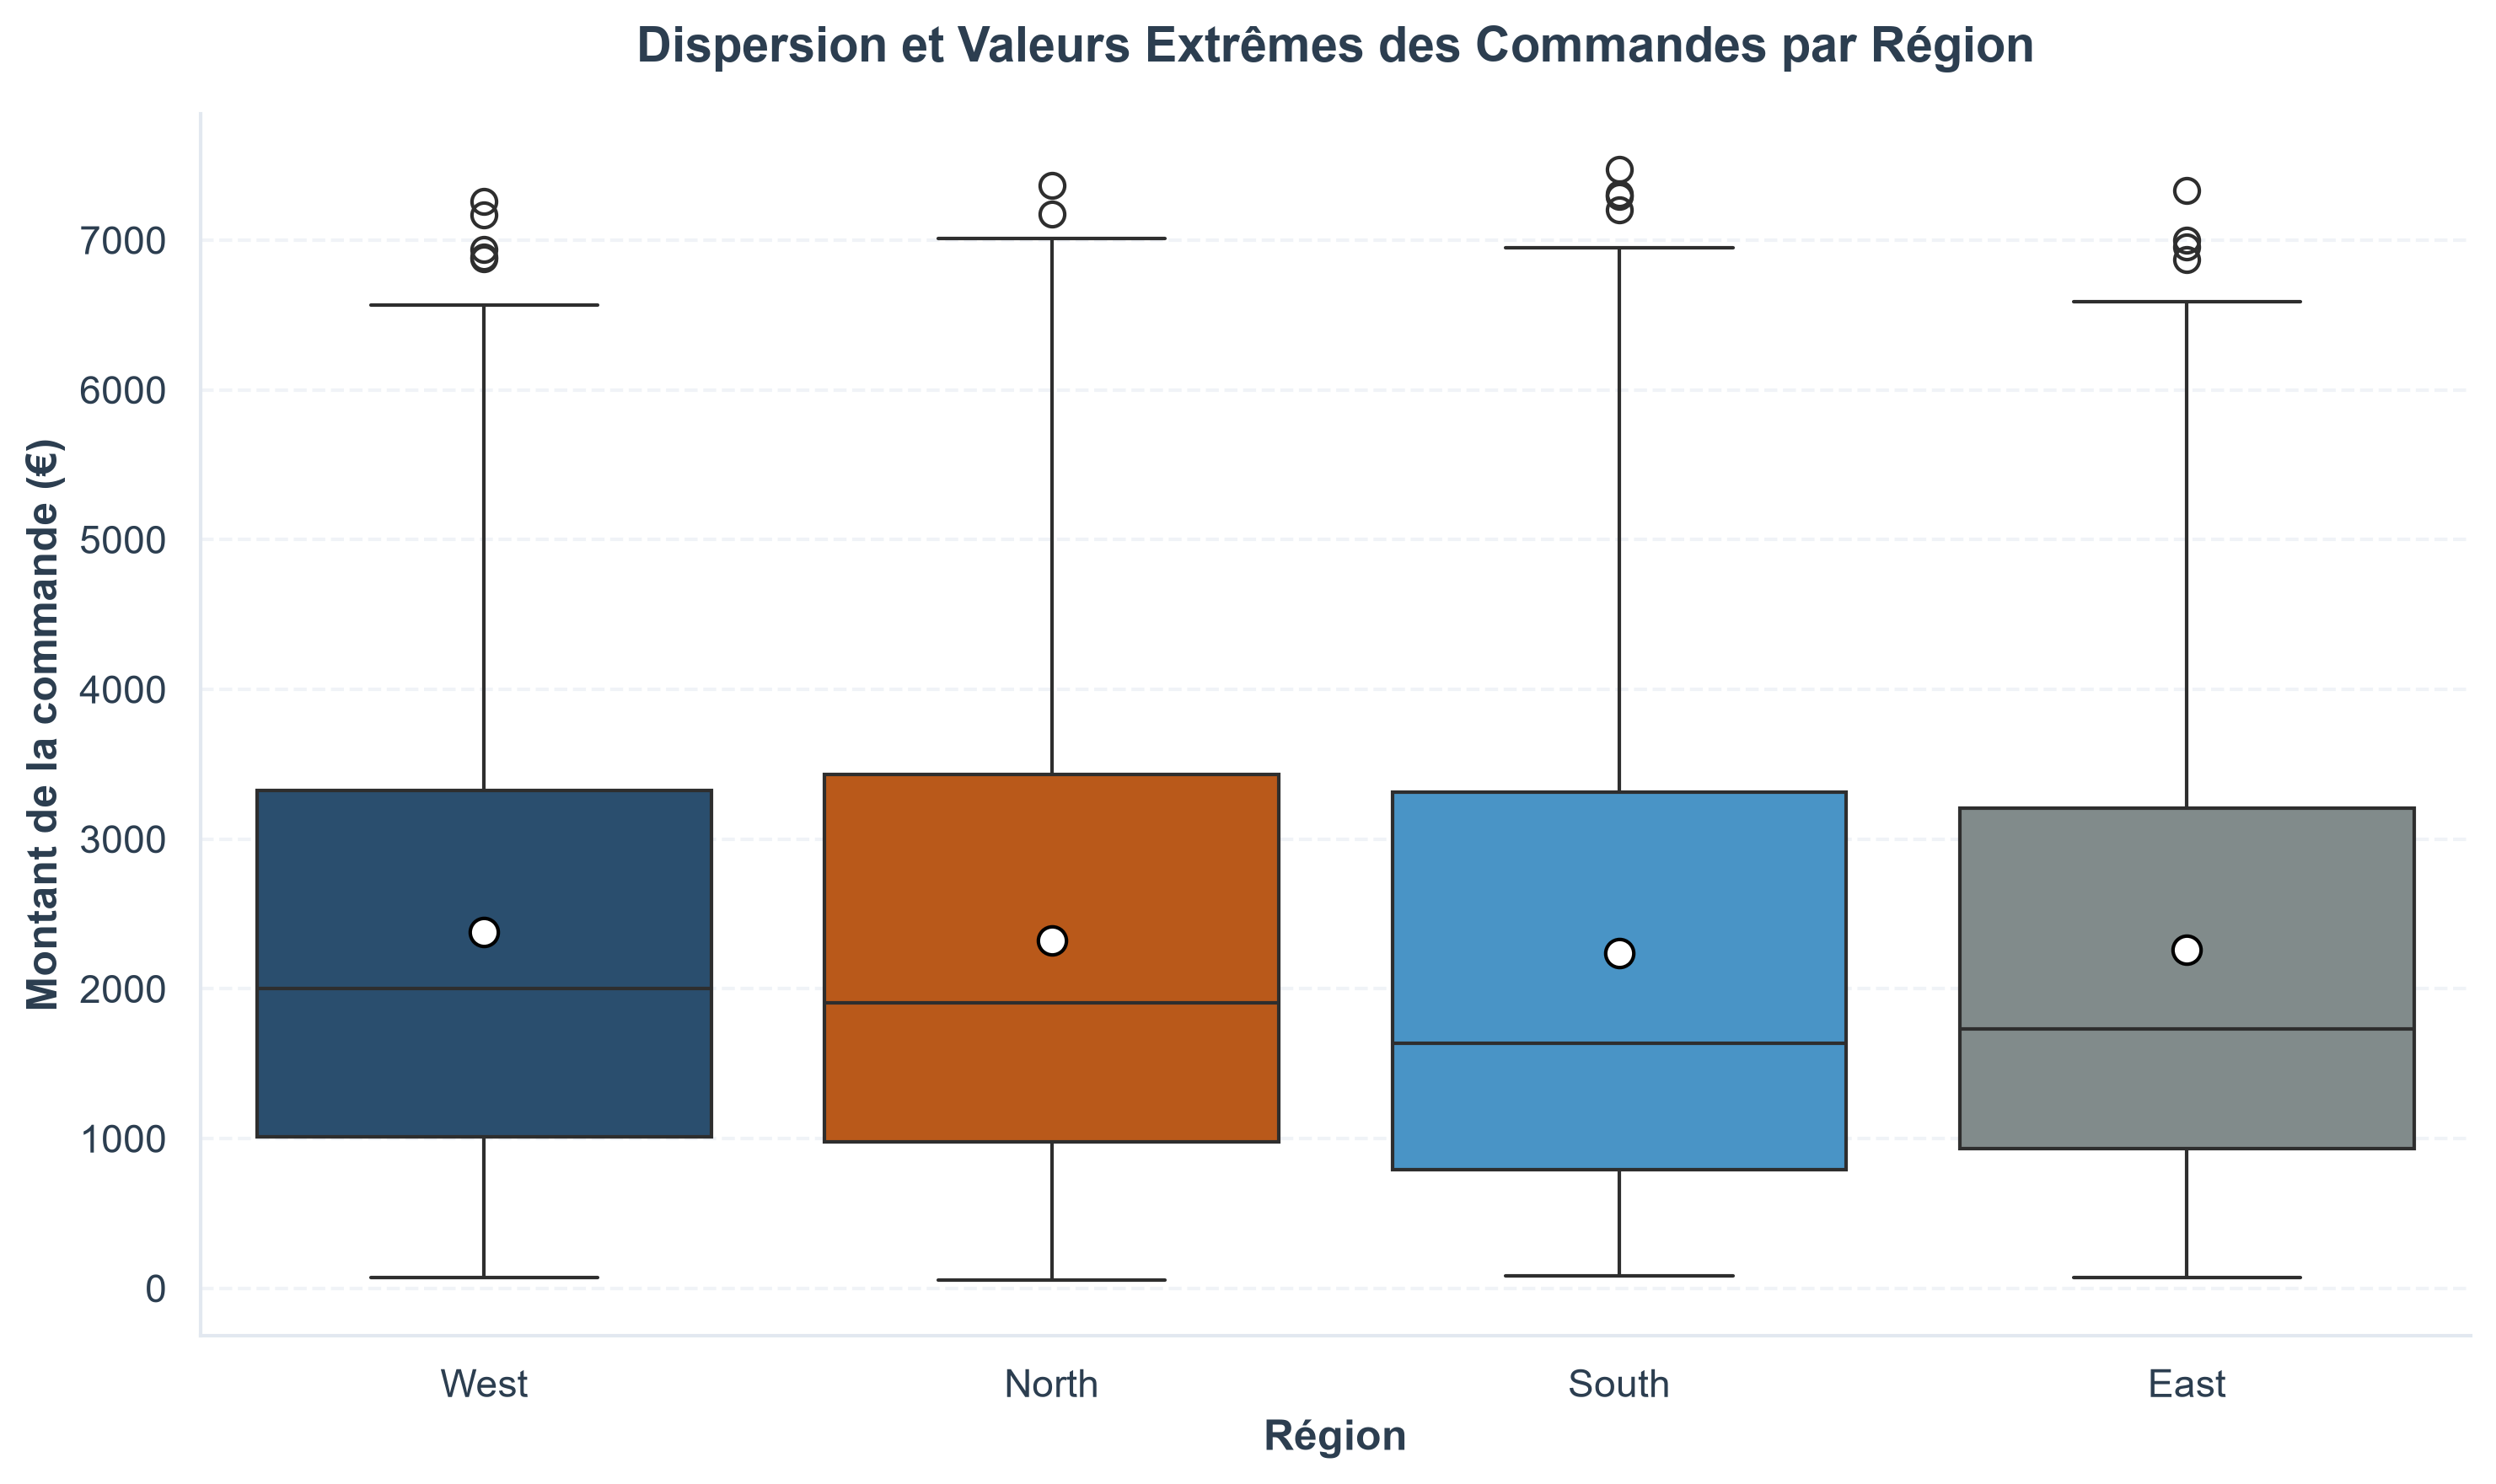

In [24]:
# ==========================================
# ÉTAPE 2.5 : Distribution des Commandes par Région (Boxplot)
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

# Création du boxplot avec seaborn
sns.boxplot(
    data=Sales, 
    x='RegionName', 
    y='TotalPrice', 
    palette=COLOR_PALETTE[:4],
    ax=ax,
    showmeans=True,  # Affiche la moyenne (croix/point blanc) en plus de la médiane (ligne)
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)

# Mise en forme
plt.title("Dispersion et Valeurs Extrêmes des Commandes par Région", size=14, fontweight='bold', pad=15)
plt.xlabel("Région", fontweight='bold')
plt.ylabel("Montant de la commande (€)", fontweight='bold')

# Nettoyage des axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 💡 Interprétation de la dispersion des commandes

* **Une homogénéité des comportements d'achat :** Les boîtes à moustaches des quatre régions se superposent presque trait pour trait, confirmant que le modèle de vente B2B génère des paniers de tailles similaires sur tout le territoire.
* **Présence de commandes d'envergure similaire :** On observe dans chaque région le même profil de valeurs extrêmes au-delà de 7 000 €, signifiant que les "gros" clients ou les commandes volumineuses ne sont pas l'apanage d'une seule zone géographique.
* **Conclusion :** La domination en chiffre d'affaires de certaines régions ne vient donc pas d'une structure de prix ou de paniers plus élevés, mais bien d'un volume cumulé de transactions plus important.